In [ ]:
import os
import pickle
from scripts.utils import path_to_save
import matplotlib.pyplot as plt

In [2]:
with open(os.path.join(path_to_save, 'target_classification.pkl'), 'rb') as f:
    results = pickle.load(f)

real_results = results['real_results']
null_results = results['null_results']
reveal_percentages = results['settings']['reveal_percentages']
conditions = results['settings']['conditions']
fractions = [16.6,50,100]

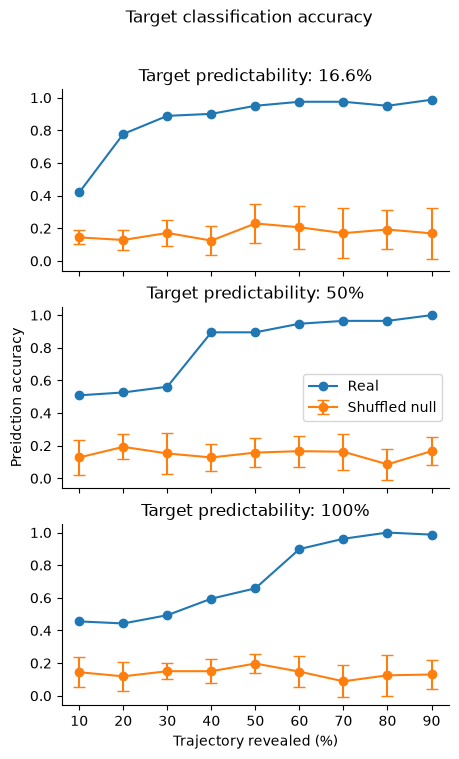

In [3]:
# Plot accuracy of predicted target id across conditions
fig, axes = plt.subplots(len(conditions),1,figsize=(5,8),sharex=True,sharey=True)

for n, (ax, condition) in enumerate(zip(axes, conditions)):

    real_acc = [real_results[condition][p]['accuracy']
                for p in reveal_percentages]

    null_acc = [null_results[condition][p]['accuracies']
                for p in reveal_percentages]

    null_means = [a.mean() for a in null_acc]
    null_stds = [a.std() for a in null_acc]

    ax.plot(reveal_percentages, real_acc, marker='o', label='Real')

    ax.errorbar(reveal_percentages, null_means, yerr=null_stds, marker='o', 
                capsize=4, label='Shuffled null')

    ax.set_title(f'Target predictability: {fractions[n]}%')
    if n == 1: ax.set_ylabel('Preidction accuracy')
    if n == 2: ax.set_xlabel('Trajectory revealed (%)')
    ax.spines[['right','top']].set_visible(False)

fig.suptitle('Target classification accuracy')
axes[1].legend()